# Lecture 6: Exploratory Data Analysis

Simplified lecture companion: Student Performance. Run cells from top to bottom. Code comments and explanations are in English. The presentation is unchanged.

Google Drive access below follows the original notebook. Alternatively, upload Student_Performance.csv to the Colab Files panel and use its local filename when reading the CSV. Outputs have been cleared so they match your next run.

## 1. Load and inspect data

Keep the established Google Drive workflow. Authentication is interactive.

In [1]:
required_packages <- c("googledrive", "ggplot2", "corrplot")
missing_packages <- setdiff(required_packages, rownames(installed.packages()))
if (length(missing_packages) > 0) {
  install.packages(missing_packages, repos = "https://cloud.r-project.org")
}
library(ggplot2)
library(corrplot)
options(repr.plot.width = 8, repr.plot.height = 5)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

corrplot 0.95 loaded



In [2]:
library(googledrive)

In [3]:
# Authenticate using the browser-based instructions
drive_auth(use_oob = TRUE)

Is it OK to cache OAuth access credentials in the folder ~/.cache/gargle
between R sessions?
1: Yes
2: No


Selection: 1


Please point your browser to the following url: 

https://accounts.google.com/o/oauth2/v2/auth?client_id=603366585132-frjlouoa3s2ono25d2l9ukvhlsrlnr7k.apps.googleusercontent.com&scope=https%3A%2F%2Fwww.googleapis.com%2Fauth%2Fdrive%20https%3A%2F%2Fwww.googleapis.com%2Fauth%2Fuserinfo.email&redirect_uri=https%3A%2F%2Fwww.tidyverse.org%2Fgoogle-callback%2F&response_type=code&state=844fde50cef757b725f058820b4ded03&access_type=offline&prompt=consent



Enter authorization code: eyJjb2RlIjoiNC8wQVVuNkhkX1NjMmFDc1lrSWhMbS1yd2R6ZGs3MkdlanNWLVpCVjhmdGNER3NIaVBNVFN3U1Nqc0FXd0IzUVRuZGdqVW9tZyIsInN0YXRlIjoiODQ0ZmRlNTBjZWY3NTdiNzI1ZjA1ODgyMGI0ZGVkMDMifQ==


In [4]:
folder_url <- "https://drive.google.com/drive/folders/1xYrk37RHG4s2-koX-e6NKEgsGAbIT8s7"

project_folder <- drive_get(as_id(folder_url))

folder_files <- drive_ls(project_folder)

print(folder_files)

# A dribble: 5 × 3
  name                    id                                drive_resource   
  <chr>                   <drv_id>                          <list>           
1 Topic_6_R.ipynb         1V2FkfJT2NqyZ1gWsaEWeFdLW0QMWUL-0 <named list [46]>
2 Topic_6_Python.ipynb    165Cm3g02fjUzvnOJKRd7BMPIh3AIt89G <named list [46]>
3 Topic_6.pdf             1rbkvdYmsOtTj3vWYcmX9UNsXwHZW9Sfh <named list [46]>
4 Student_Performance.csv 1IQwSsDDh1IRSIe3oXdKjnVXvO3cRVSVc <named list [45]>
5 house_data.csv          1XgGHPE4hEBjvcLOFAQG9Ogp2ERqcky60 <named list [45]>


In [5]:
dataset_file <- folder_files[
  folder_files$name == "Student_Performance.csv",
]

if (nrow(dataset_file) != 1) {
  stop("Expected exactly one file named Student_Performance.csv in the project folder.")
}

drive_download(
  dataset_file,
  path = "Student_Performance.csv",
  overwrite = TRUE
)

df <- read.csv(
  "Student_Performance.csv",
  check.names = FALSE,
  stringsAsFactors = FALSE
)

cat(
  "Dataset loaded:",
  nrow(df), "rows,",
  ncol(df), "columns\n"
)

head(df)

File downloaded:

• Student_Performance.csv <id: 1IQwSsDDh1IRSIe3oXdKjnVXvO3cRVSVc>

Saved locally as:

• Student_Performance.csv



Dataset loaded: 10000 rows, 6 columns


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
,<int>,<int>,<chr>,<int>,<int>,<dbl>
1,7,99,Yes,9,1,91
2,4,82,No,4,2,65
3,8,51,Yes,7,2,45
4,5,52,Yes,5,2,36
5,7,75,No,8,5,66
6,3,78,No,9,6,61


In [6]:
cat("DATASET DIMENSIONS\n")
cat("Rows:", nrow(df), ", columns:", ncol(df), "\n")

cat("\nFIRST FIVE ROWS\n")
print(head(df, 5))

cat("\nDATA TYPES AND STRUCTURE\n")
str(df)

cat("\nMISSING VALUES PER COLUMN\n")
print(data.frame(
  Variable = names(df),
  Missing_values = colSums(is.na(df)),
  row.names = NULL
))

cat("\nDUPLICATE ROWS\n")
cat("Number of duplicate rows:", sum(duplicated(df)), "\n")

cat("\nSUMMARY OF ALL COLUMNS\n")
print(summary(df))

cat("\nCATEGORICAL VALUE COUNTS\n")
print(table(
  df[["Extracurricular Activities"]],
  useNA = "ifany"
))

DATASET DIMENSIONS
Rows: 10000 , columns: 6 

FIRST FIVE ROWS
  Hours Studied Previous Scores Extracurricular Activities Sleep Hours
1             7              99                        Yes           9
2             4              82                         No           4
3             8              51                        Yes           7
4             5              52                        Yes           5
5             7              75                         No           8
  Sample Question Papers Practiced Performance Index
1                                1                91
2                                2                65
3                                2                45
4                                2                36
5                                5                66

DATA TYPES AND STRUCTURE
'data.frame':	10000 obs. of  6 variables:
 $ Hours Studied                   : int  7 4 8 5 7 3 7 8 5 4 ...
 $ Previous Scores                 : int  99 82 51 52 75 78 

## 2. Central tendency

Report all modes when several values have the same highest frequency. R mode() describes storage type, so we use a short statistical_mode() function.

In [7]:
statistical_mode <- function(x) {
  frequencies <- table(x)
  names(frequencies)[frequencies == max(frequencies)]
}
numeric_df <- df[sapply(df, is.numeric)]
central_tendency <- data.frame(
  Mean = sapply(numeric_df, mean, na.rm = TRUE),
  Median = sapply(numeric_df, median, na.rm = TRUE)
)
central_tendency <- round(central_tendency, 3)
central_tendency$Modes <- sapply(numeric_df, function(x) {
  paste(statistical_mode(x), collapse = ", ")
})
print(central_tendency)
print(statistical_mode(df[["Extracurricular Activities"]]))

                                   Mean Median Modes
Hours Studied                     4.993      5     1
Previous Scores                  69.446     69    54
Sleep Hours                       6.531      7     8
Sample Question Papers Practiced  4.583      5     6
Performance Index                55.225     55    67
[1] "No"


## 3. Effect of an extreme value

Replacing 8 with 28 changes the mean from 4 to 8. Median and mode remain 3.

In [8]:
original <- c(2, 3, 3, 4, 8)
modified <- c(2, 3, 3, 4, 28)
for (x in list(original, modified)) {
  cat("Values:", x, "
")
  cat("Mean:", mean(x), "Median:", median(x), "Modes:", statistical_mode(x), "
")
}

Values: 2 3 3 4 8 
Mean: 4 Median: 3 Modes: 3 
Values: 2 3 3 4 28 
Mean: 8 Median: 3 Modes: 3 


## 4. Variability and five-number summary

Both languages use sample variance (n - 1 denominator). Default quantiles agree: linear interpolation in pandas and type 7 in R. Summaries omit missing values separately for each variable.

In [9]:
q1 <- sapply(numeric_df, quantile, probs = 0.25, na.rm = TRUE, names = FALSE)
q3 <- sapply(numeric_df, quantile, probs = 0.75, na.rm = TRUE, names = FALSE)
summary_table <- data.frame(
  Count = sapply(numeric_df, function(x) sum(!is.na(x))),
  Mean = sapply(numeric_df, mean, na.rm = TRUE),
  Variance = sapply(numeric_df, var, na.rm = TRUE),
  SD = sapply(numeric_df, sd, na.rm = TRUE),
  Min = sapply(numeric_df, min, na.rm = TRUE),
  Q1 = q1,
  Median = sapply(numeric_df, median, na.rm = TRUE),
  Q3 = q3,
  Max = sapply(numeric_df, max, na.rm = TRUE)
)
summary_table$Range <- summary_table$Max - summary_table$Min
summary_table$IQR <- q3 - q1
print(round(summary_table, 3))

                                 Count   Mean Variance     SD Min Q1 Median Q3
Hours Studied                    10000  4.993    6.705  2.589   1  3      5  7
Previous Scores                  10000 69.446  300.785 17.343  40 54     69 85
Sleep Hours                      10000  6.531    2.876  1.696   4  5      7  8
Sample Question Papers Practiced 10000  4.583    8.222  2.867   0  2      5  7
Performance Index                10000 55.225  369.122 19.213  10 40     55 71
                                 Max Range IQR
Hours Studied                      9     8   4
Previous Scores                   99    59  31
Sleep Hours                        9     5   3
Sample Question Papers Practiced   9     9   5
Performance Index                100    90  31


## 5. Same mean, different spread

Both means equal 5; variances are 1 and 25; standard deviations are 1 and 5.

In [10]:
for (x in list(c(4, 5, 6), c(0, 5, 10))) {
  cat("Values:", x, "
")
  cat("Mean:", mean(x), "Variance:", var(x), "SD:", sd(x), "Range:", max(x) - min(x), "
")
}

Values: 4 5 6 
Mean: 5 Variance: 1 SD: 1 Range: 2 
Values: 0 5 10 
Mean: 5 Variance: 25 SD: 5 Range: 10 


## 6. Quantiles: values 1 to 9

Expected five-number summary: 1, 3, 5, 7, 9.

In [11]:
print(quantile(1:9, probs = c(0, 0.25, 0.5, 0.75, 1)))

  0%  25%  50%  75% 100% 
   1    3    5    7    9 


## 7. Histograms

Inspect symmetry, tails, peaks and gaps. Red and green lines may overlap. Bin edges are matched between environments.

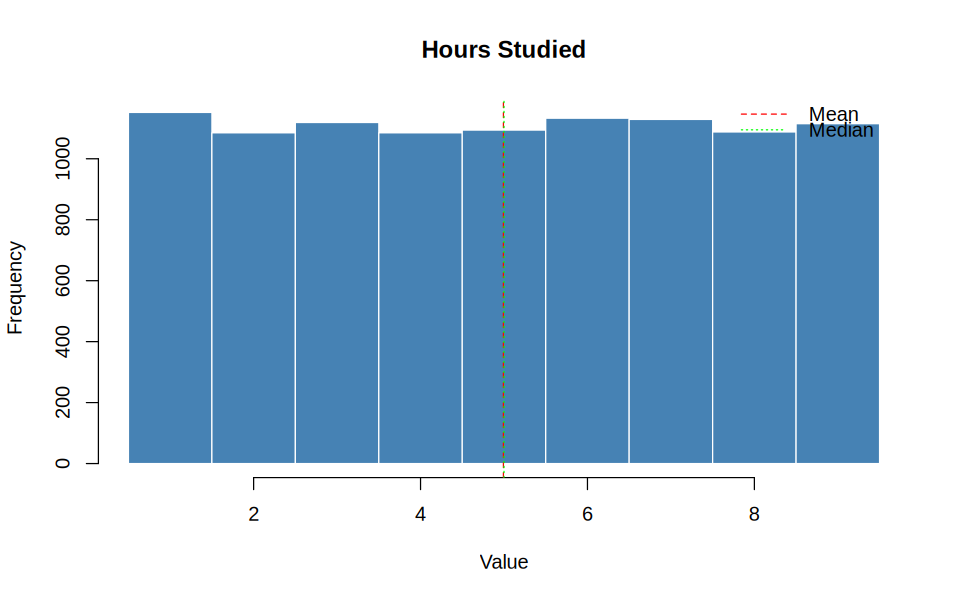

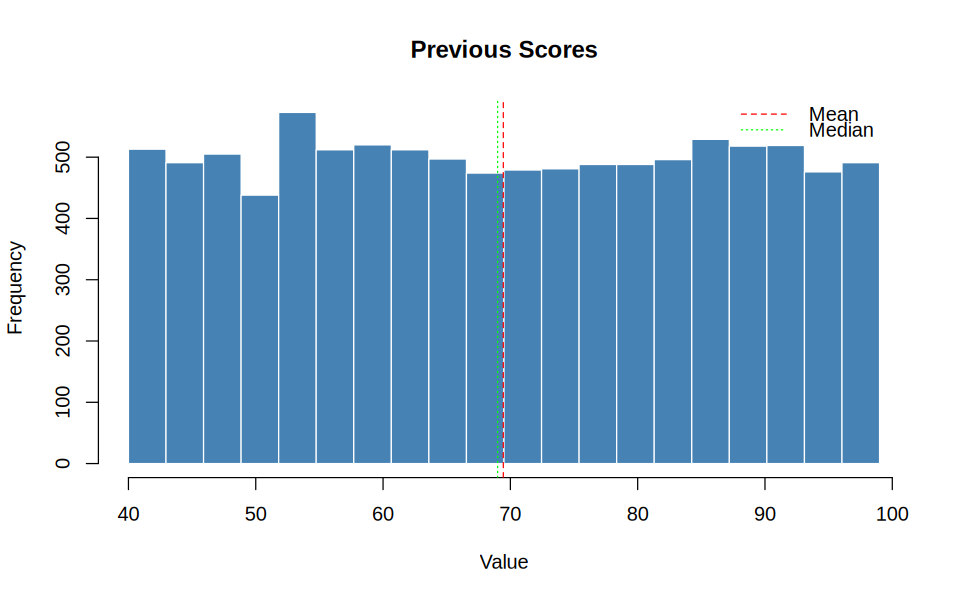

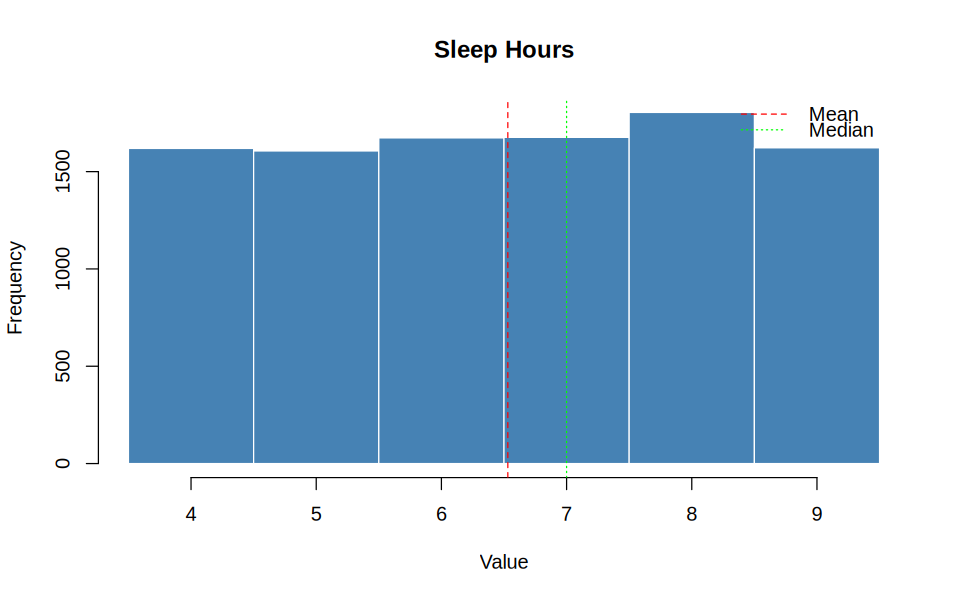

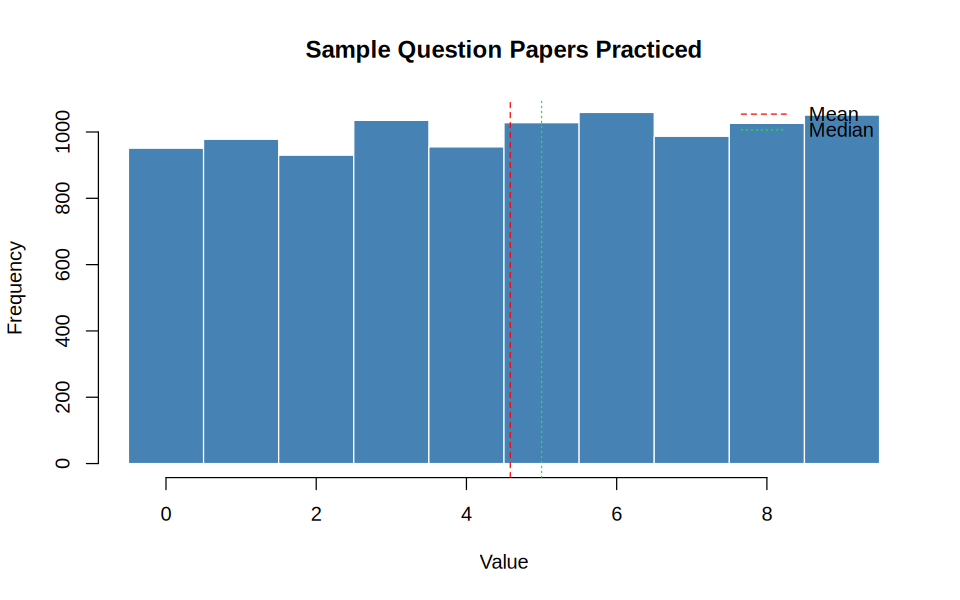

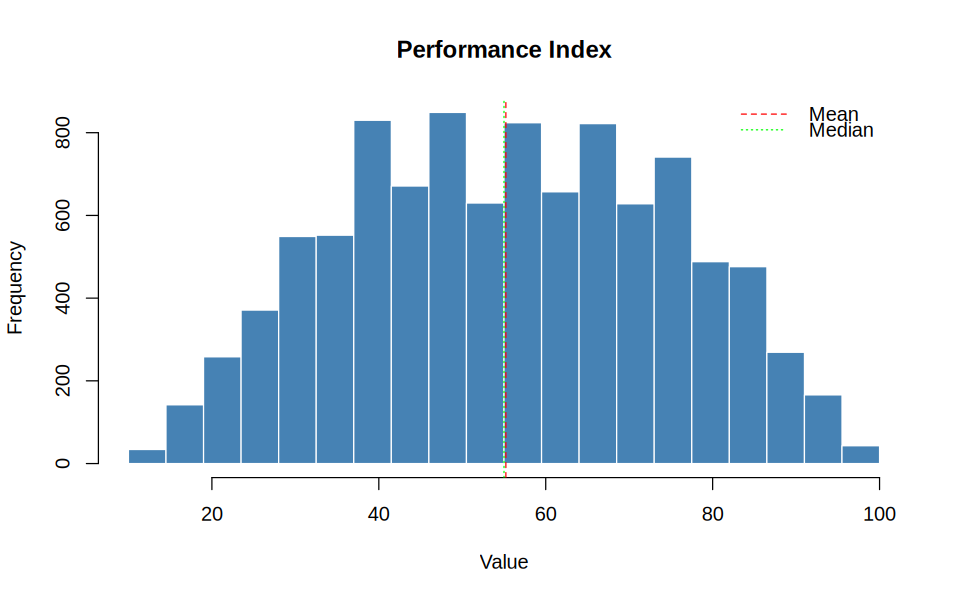

In [12]:
for (column in names(numeric_df)) {
  x <- na.omit(numeric_df[[column]])
  # Align bins with integer values when there are few distinct values.
  if (length(unique(x)) <= 15 && all(x %% 1 == 0)) {
    breaks <- seq(min(x) - 0.5, max(x) + 0.5, by = 1)
  } else {
    breaks <- seq(min(x), max(x), length.out = 21)
  }
  hist(x, breaks = breaks, right = FALSE, main = column,
       xlab = "Value", ylab = "Frequency", col = "steelblue", border = "white")
  abline(v = mean(x), col = "red", lty = 2)
  abline(v = median(x), col = "green", lty = 3)
  legend("topright", c("Mean", "Median"), col = c("red", "green"), lty = c(2, 3), bty = "n")
}

## 8. Category frequencies

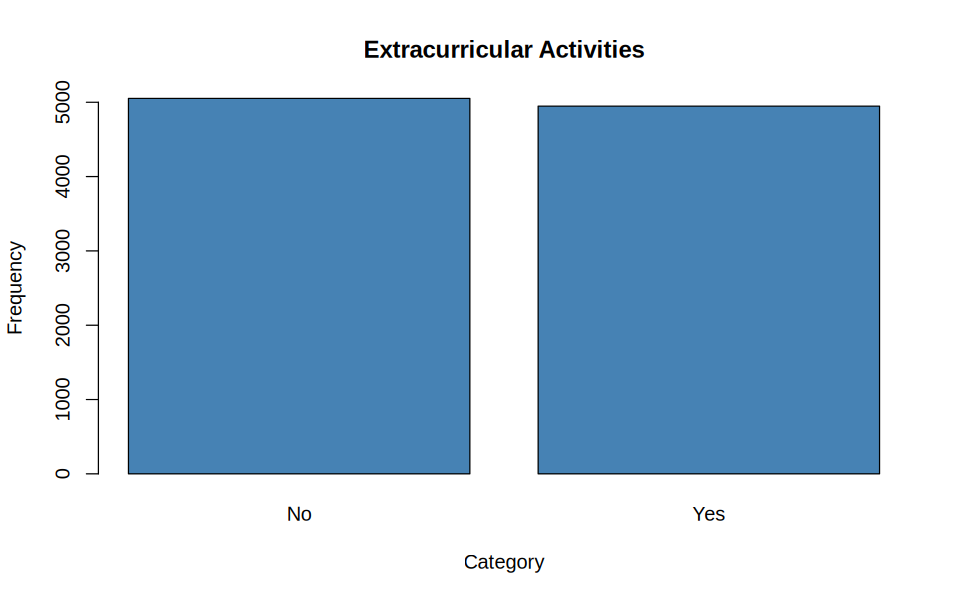

In [13]:
barplot(table(df[["Extracurricular Activities"]], useNA = "ifany"),
        main = "Extracurricular Activities", xlab = "Category",
        ylab = "Frequency", col = "steelblue")

## 9. Boxplots

Points outside whiskers are potential outliers, not automatically errors. R base boxplot uses Tukey hinges; for small samples they can differ from type-7 quartiles. The explicit IQR screening below uses matching quartiles in both languages.

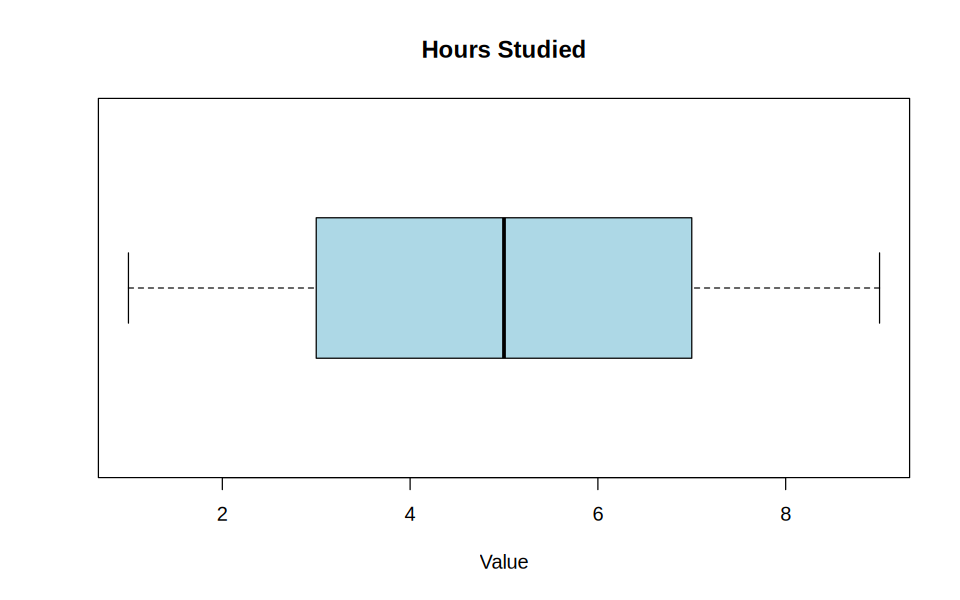

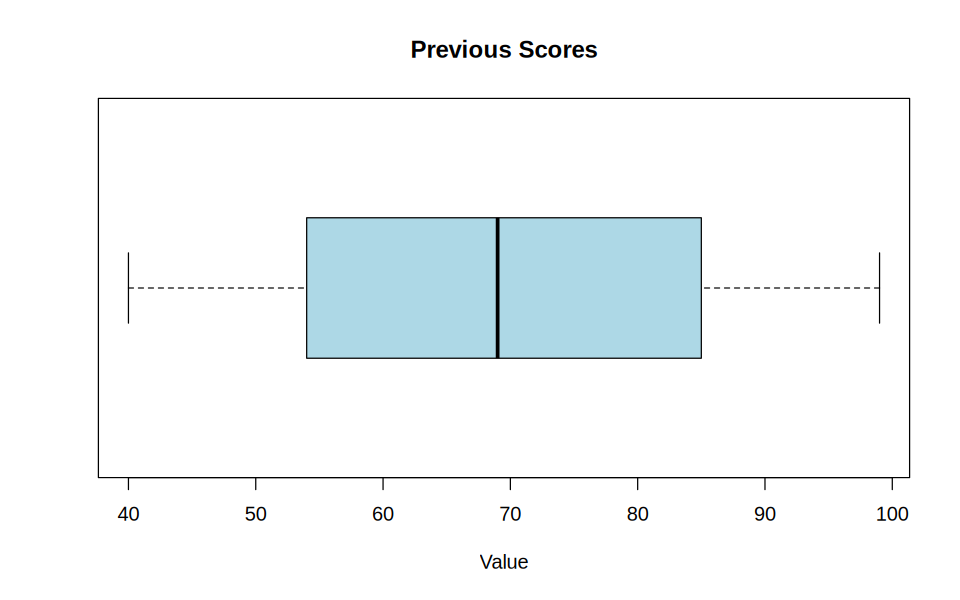

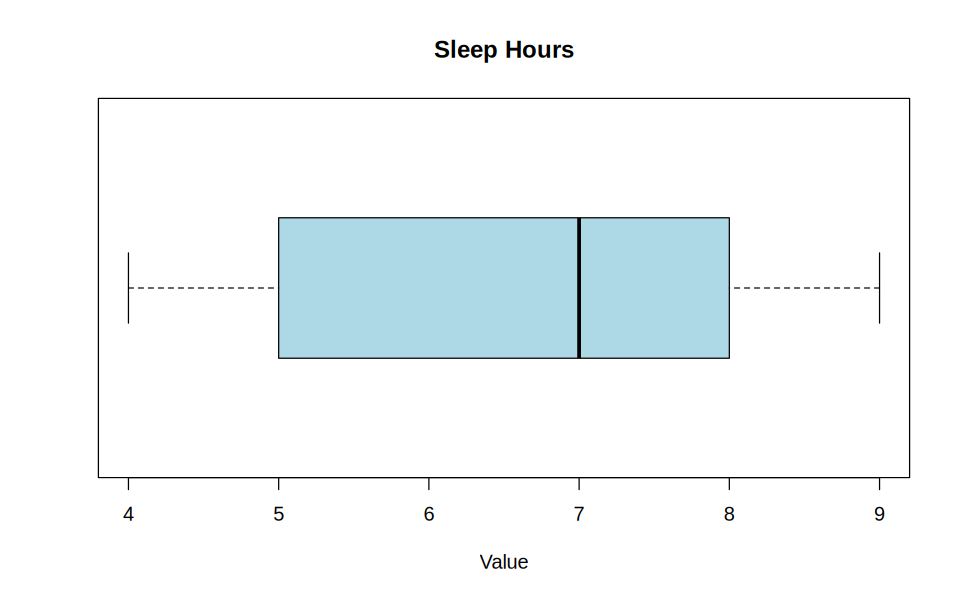

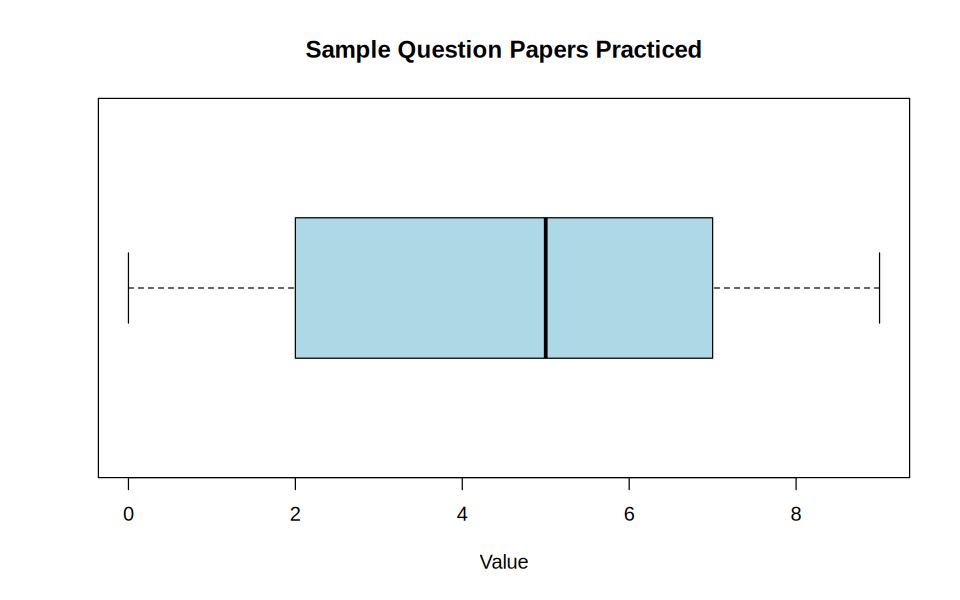

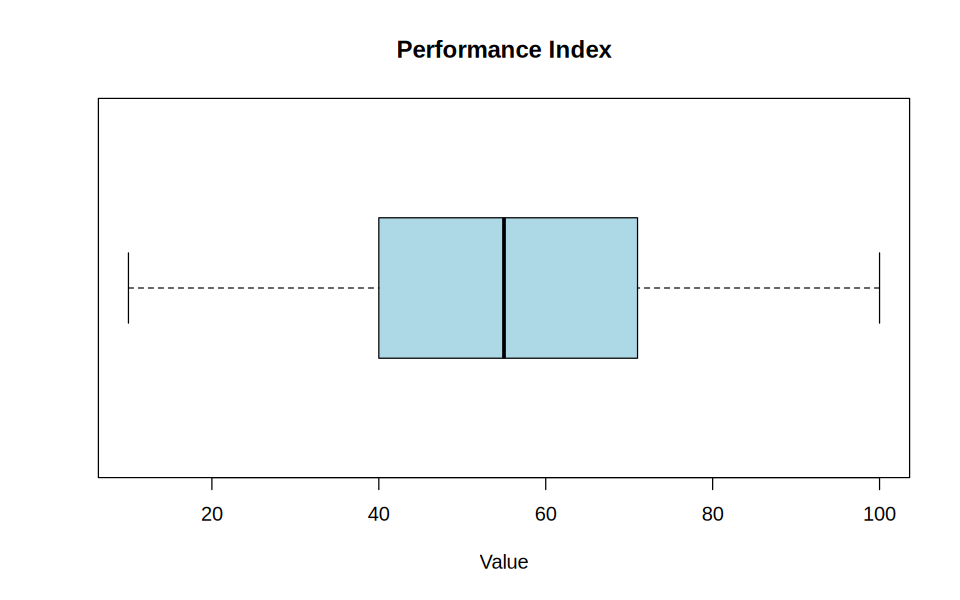

In [14]:
for (column in names(numeric_df)) {
  boxplot(numeric_df[[column]], horizontal = TRUE,
          main = column, xlab = "Value", col = "lightblue")
}

## 10. Potential outliers: the IQR rule

Investigate flagged records. Keep the original data; do not automatically remove observations. An empty result means no rows were flagged.

In [15]:
iqr <- q3 - q1
lower_limits <- q1 - 1.5 * iqr
upper_limits <- q3 + 1.5 * iqr
outlier_mask <- numeric_df
for (column in names(numeric_df)) {
  x <- numeric_df[[column]]
  outlier_mask[[column]] <- x < lower_limits[column] | x > upper_limits[column]
}
outlier_summary <- data.frame(
  Lower_limit = lower_limits,
  Upper_limit = upper_limits,
  Flagged_count = colSums(outlier_mask, na.rm = TRUE)
)
print(round(outlier_summary, 3))
flagged_rows <- rowSums(outlier_mask, na.rm = TRUE) > 0
print(head(df[flagged_rows, ], 10))

                                 Lower_limit Upper_limit Flagged_count
Hours Studied                           -3.0        13.0             0
Previous Scores                          7.5       131.5             0
Sleep Hours                              0.5        12.5             0
Sample Question Papers Practiced        -5.5        14.5             0
Performance Index                       -6.5       117.5             0
[1] Hours Studied                    Previous Scores                 
[3] Extracurricular Activities       Sleep Hours                     
[5] Sample Question Papers Practiced Performance Index               
<0 rows> (or 0-length row.names)


## 11. Compare groups

Compare group sizes, location, spread and overlap. The mean difference is descriptive and does not establish causality.

    Count   Mean Median     SD IQR
No   5052 54.759     55 19.152  30
Yes  4948 55.701     55 19.264  30
Mean difference (Yes - No): 0.9423778 


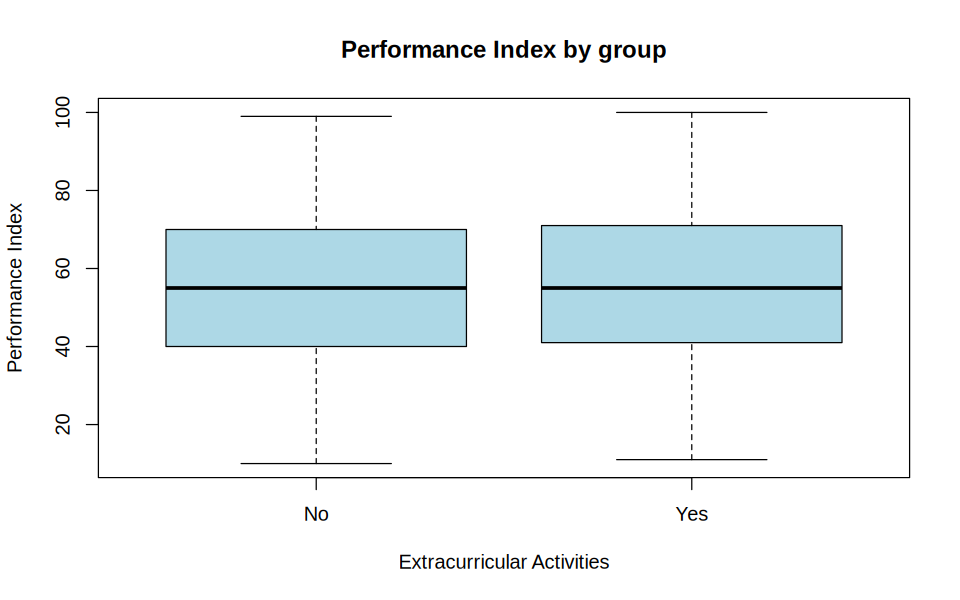

In [16]:
group_column <- "Extracurricular Activities"
target <- "Performance Index"
groups <- split(df[[target]], df[[group_column]])
group_summary <- data.frame(
  Count = sapply(groups, function(x) sum(!is.na(x))),
  Mean = sapply(groups, mean, na.rm = TRUE),
  Median = sapply(groups, median, na.rm = TRUE),
  SD = sapply(groups, sd, na.rm = TRUE),
  IQR = sapply(groups, IQR, na.rm = TRUE)
)
print(round(group_summary, 3))
cat("Mean difference (Yes - No):", group_summary["Yes", "Mean"] - group_summary["No", "Mean"], "
")
boxplot(groups[c("No", "Yes")], main = "Performance Index by group",
        xlab = group_column, ylab = target, col = "lightblue")

## 12. Scatterplots and local smoothing

Both examples use local linear fits without robust iterations. LOWESS and LOESS implementations differ, so curves need not be identical. Repeated x values are common; evaluate at distinct x values. Very small spans may fail when too few distinct predictor values enter a neighborhood.

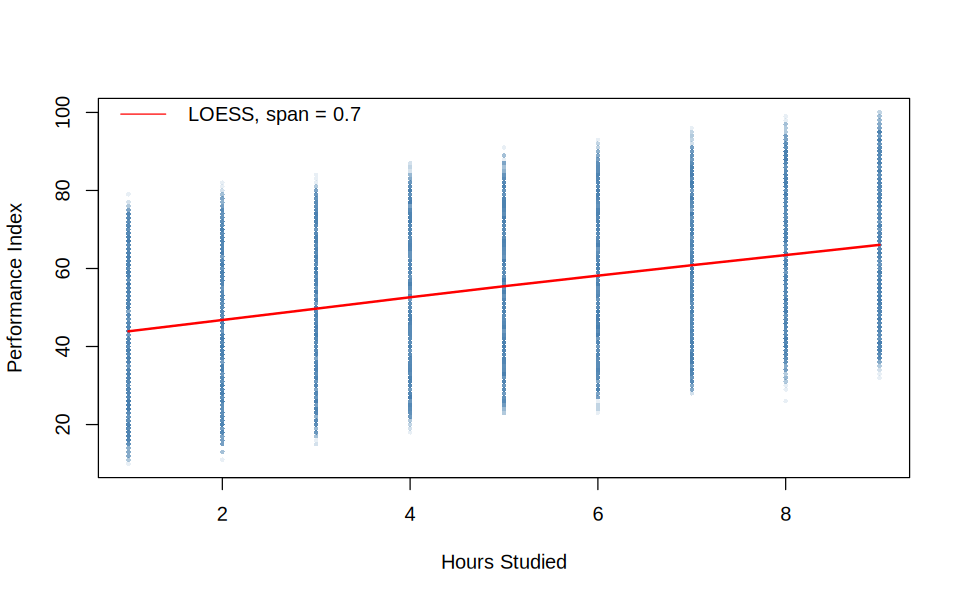

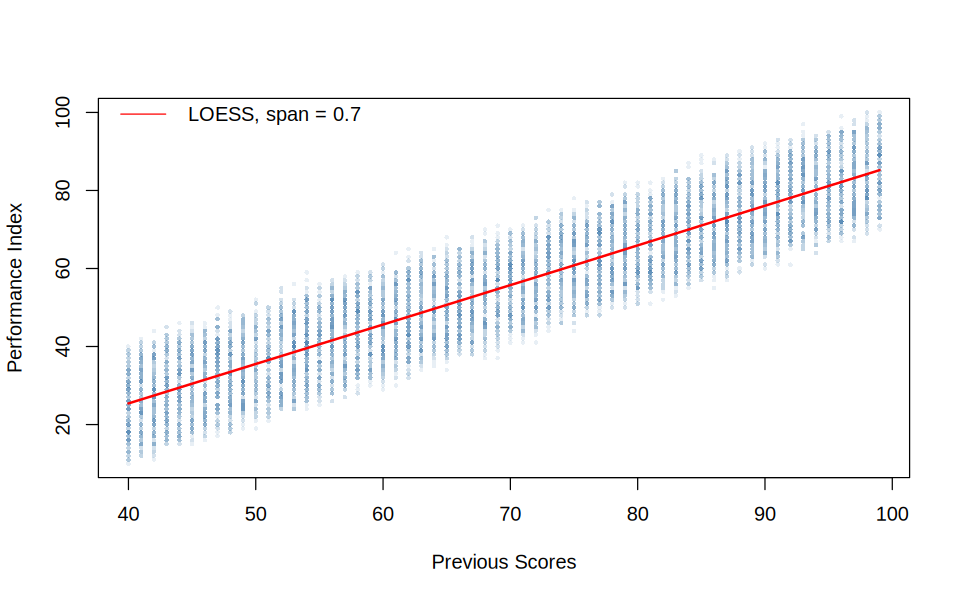

In [17]:
predictors <- c("Hours Studied", "Previous Scores")
span <- 0.7
for (predictor in predictors) {
  pair_data <- na.omit(data.frame(x = df[[predictor]], y = df[[target]]))
  fit <- loess(y ~ x, data = pair_data, span = span, degree = 1, family = "gaussian")
  x_grid <- sort(unique(pair_data$x))
  trend <- predict(fit, newdata = data.frame(x = x_grid))
  plot(pair_data$x, pair_data$y, pch = 16, cex = 0.5,
       col = adjustcolor("steelblue", alpha.f = 0.12), xlab = predictor, ylab = target)
  lines(x_grid, trend, col = "red", lwd = 2)
  legend("topleft", paste("LOESS, span =", span), col = "red", lty = 1, bty = "n")
}

## 13. Compare smoothing spans

Smaller spans reveal more local detail. On approximately linear data, the curves may be very similar.

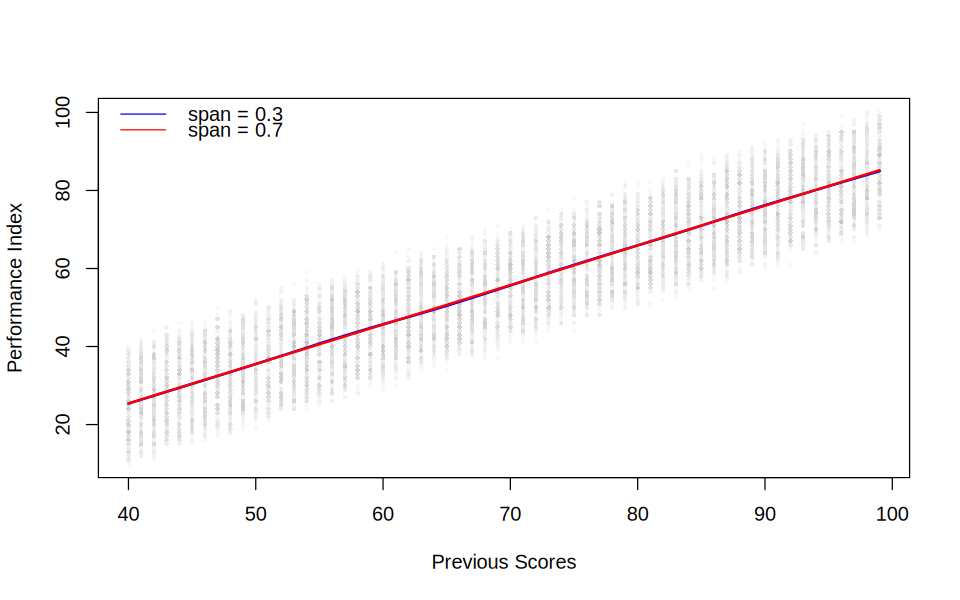

In [18]:
pair_data <- na.omit(data.frame(x = df[["Previous Scores"]], y = df[[target]]))
x_grid <- sort(unique(pair_data$x))
plot(pair_data$x, pair_data$y, pch = 16, cex = 0.5,
     col = adjustcolor("grey", alpha.f = 0.1), xlab = "Previous Scores", ylab = target)
spans <- c(0.3, 0.7)
colors <- c("blue", "red")
for (i in seq_along(spans)) {
  fit <- loess(y ~ x, data = pair_data, span = spans[i], degree = 1, family = "gaussian")
  lines(x_grid, predict(fit, data.frame(x = x_grid)), col = colors[i], lwd = 2)
}
legend("topleft", paste("span =", spans), col = colors, lty = 1, bty = "n")

## 14. Correlation for one pair

Pearson measures linear association; Spearman and Kendall measure monotonic association. Their magnitudes are not interchangeable. Before applying this code to other data, check that selected variables vary and enough complete observations remain.

In [19]:
# Use one common complete dataset for all correlation calculations.
complete_data <- numeric_df
for (column in names(complete_data)) {
  complete_data[[column]][!is.finite(complete_data[[column]])] <- NA
}
complete_data <- na.omit(complete_data)
cat("Complete observations:", nrow(complete_data), "
")
x <- complete_data[["Hours Studied"]]
y <- complete_data[[target]]
cat("Pearson:", cor(x, y, method = "pearson"), "
")
cat("Spearman:", cor(x, y, method = "spearman"), "
")
cat("Kendall:", cor(x, y, method = "kendall"), "
")

Complete observations: 10000 
Pearson: 0.3737304 
Spearman: 0.3523947 
Kendall: 0.2547194 


## 15. Correlation matrices and heatmaps

Use the same observations, variable order and color limits for all methods. Color shows correlation, not significance.

                                 Hours Studied Previous Scores Sleep Hours
Hours Studied                            1.000          -0.012       0.001
Previous Scores                         -0.012           1.000       0.006
Sleep Hours                              0.001           0.006       1.000
Sample Question Papers Practiced         0.017           0.008       0.004
Performance Index                        0.374           0.915       0.048
                                 Sample Question Papers Practiced
Hours Studied                                               0.017
Previous Scores                                             0.008
Sleep Hours                                                 0.004
Sample Question Papers Practiced                            1.000
Performance Index                                           0.043
                                 Performance Index
Hours Studied                                0.374
Previous Scores                              0.915
S

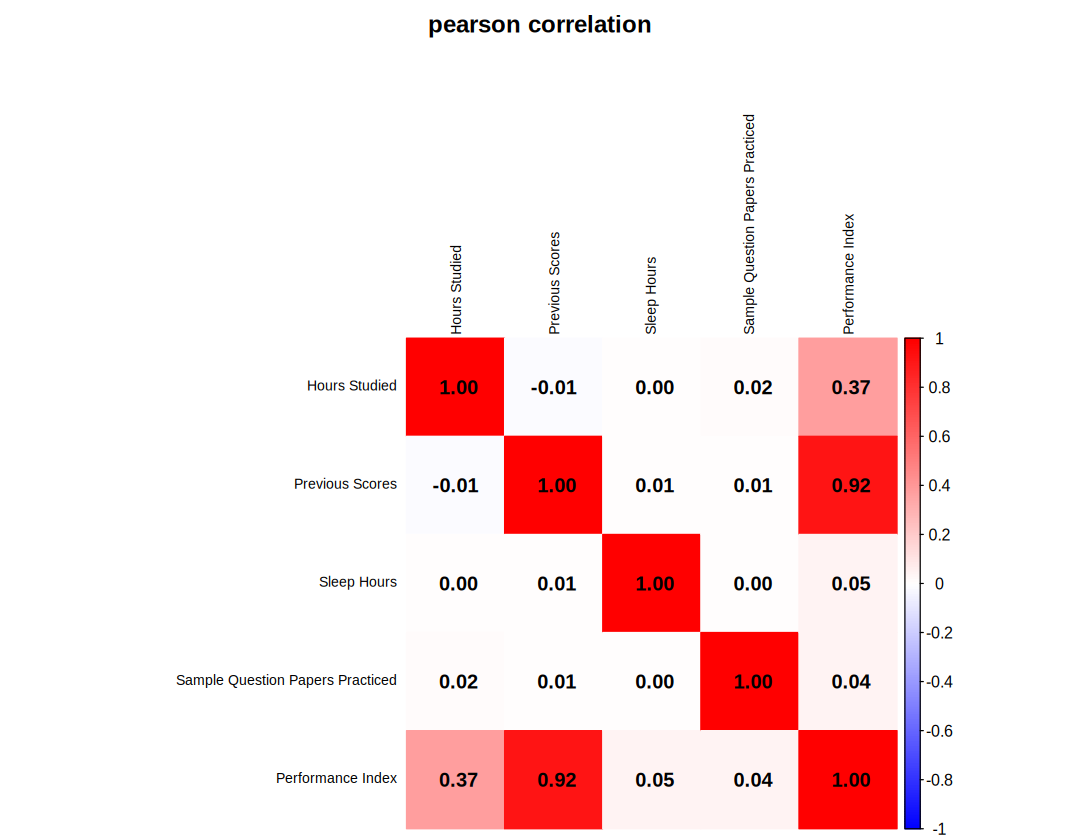

                                 Hours Studied Previous Scores Sleep Hours
Hours Studied                            1.000          -0.009       0.001
Previous Scores                         -0.009           1.000       0.004
Sleep Hours                              0.001           0.004       1.000
Sample Question Papers Practiced         0.013           0.006       0.003
Performance Index                        0.255           0.751       0.033
                                 Sample Question Papers Practiced
Hours Studied                                               0.013
Previous Scores                                             0.006
Sleep Hours                                                 0.003
Sample Question Papers Practiced                            1.000
Performance Index                                           0.029
                                 Performance Index
Hours Studied                                0.255
Previous Scores                              0.751
S

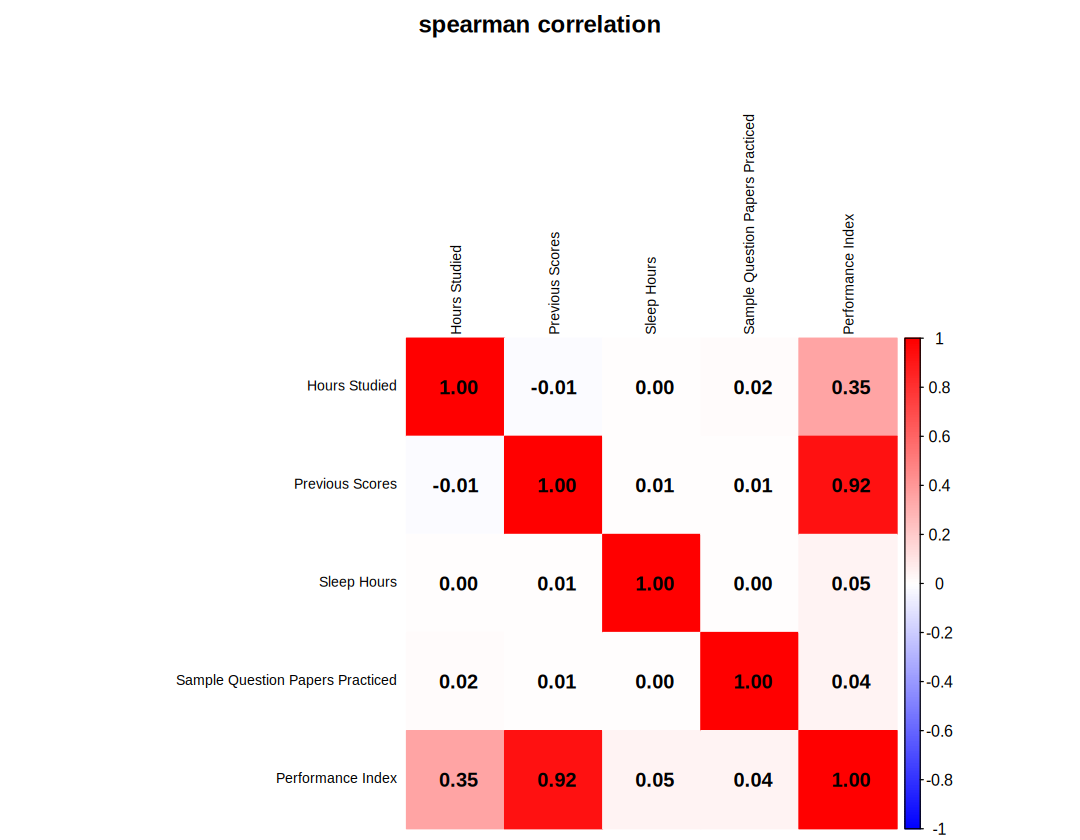

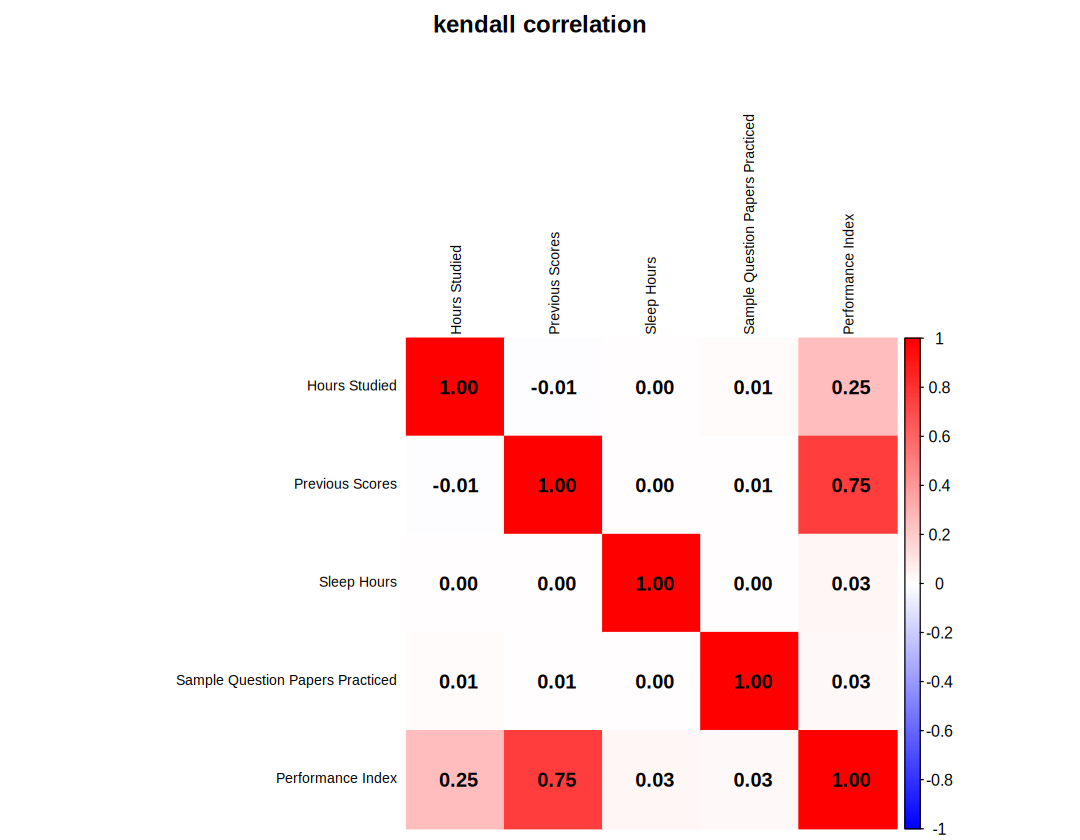

In [20]:
correlation_matrices <- list()
options(repr.plot.width = 9, repr.plot.height = 7)
for (method in c("pearson", "spearman", "kendall")) {
  matrix_result <- cor(complete_data, method = method)
  correlation_matrices[[method]] <- matrix_result
  print(round(matrix_result, 3))
  corrplot(matrix_result, method = "color", addCoef.col = "black",
           col = colorRampPalette(c("blue", "white", "red"))(200),
           col.lim = c(-1, 1), tl.col = "black", tl.cex = 0.7,
           title = paste(method, "correlation"), mar = c(0, 0, 2, 0))
}

## 16. Pearson test and confidence interval: one pair

H0: population Pearson correlation equals zero. The default test is two-sided; the confidence interval uses Fisher transformation. Classical inference assumes independent pairs and, for the exact Pearson null test, bivariate normality. A small p-value does not imply a large or causal effect.

In [21]:
x <- complete_data[["Hours Studied"]]
y <- complete_data[[target]]
test <- cor.test(x, y, method = "pearson", conf.level = 0.95)
cat("Sample size:", length(x), "
")
cat("Pearson r:", unname(test$estimate), "
")
cat("Two-sided p-value:", test$p.value, "
")
print(test$conf.int)

Sample size: 10000 
Pearson r: 0.3737304 
Two-sided p-value: 0 
[1] 0.3567435 0.3904702
attr(,"conf.level")
[1] 0.95


## 17. Multiple Pearson tests and BH correction

The test family is defined before correction: four predictor-target Pearson tests. This is a focused lecture example replacing the original 10 pairs per method. The student assignment uses six Pearson tests with MEDV as one family. Confidence intervals here are individual 95% intervals, not adjusted simultaneous intervals. BH controls false discovery rate under its usual independence or suitable positive-dependence conditions.

In [22]:
# Family: all four numerical predictors versus Performance Index.
predictors <- setdiff(names(complete_data), target)
results <- data.frame()
for (predictor in predictors) {
  test <- cor.test(complete_data[[predictor]], complete_data[[target]], method = "pearson")
  row <- data.frame(
    Variable = predictor, N = nrow(complete_data), r = unname(test$estimate),
    CI_lower = test$conf.int[1], CI_upper = test$conf.int[2], p_value = test$p.value
  )
  results <- rbind(results, row)
}
results$p_BH <- p.adjust(results$p_value, method = "BH")
results$Reject_H0_BH <- results$p_BH < 0.05
print(results, row.names = FALSE)

                         Variable     N          r   CI_lower   CI_upper
                    Hours Studied 10000 0.37373035 0.35674348 0.39047017
                  Previous Scores 10000 0.91518914 0.91194737 0.91831666
                      Sleep Hours 10000 0.04810584 0.02853267 0.06764213
 Sample Question Papers Practiced 10000 0.04326833 0.02368835 0.06281513
      p_value         p_BH Reject_H0_BH
 0.000000e+00 0.000000e+00         TRUE
 0.000000e+00 0.000000e+00         TRUE
 1.488537e-06 1.984716e-06         TRUE
 1.502519e-05 1.502519e-05         TRUE


## 18. Visualize Pearson uncertainty

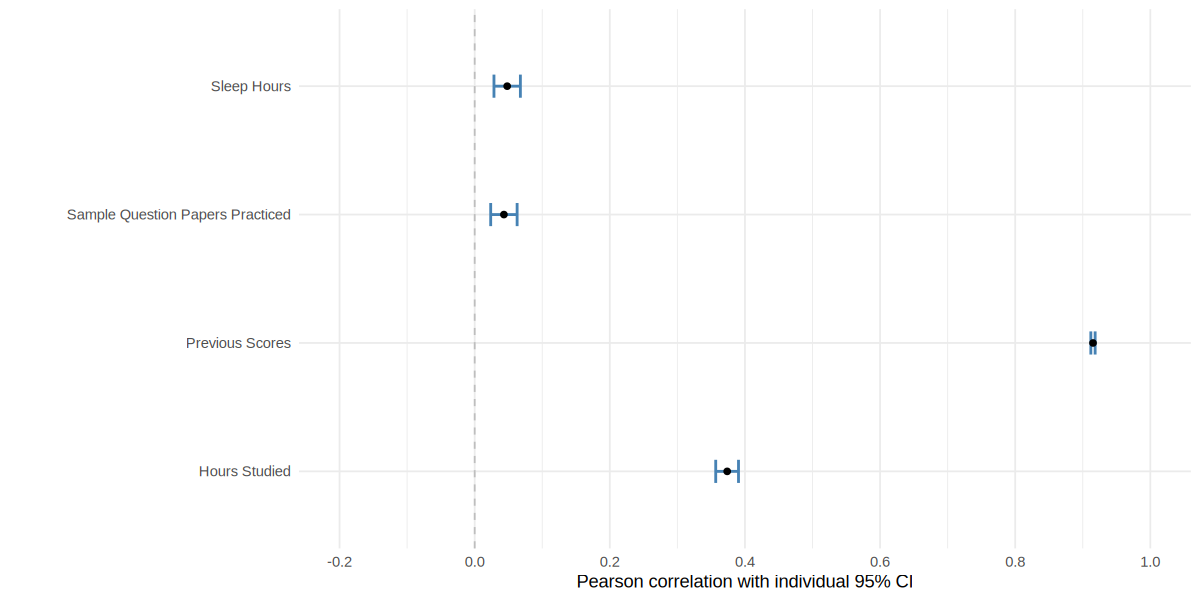

In [23]:
options(repr.plot.width = 10, repr.plot.height = 5)

ggplot(results, aes(x = r, y = Variable)) +
  geom_vline(
    xintercept = 0,
    linetype = "dashed",
    color = "grey"
  ) +
  geom_errorbar(
    aes(xmin = CI_lower, xmax = CI_upper),
    orientation = "y",
    width = 0.18,
    linewidth = 0.8,
    color = "steelblue"
  ) +
  geom_point(size = 1.5) +
  scale_x_continuous(
    limits = c(-0.2, 1),
    breaks = seq(-0.2, 1, by = 0.2)
  ) +
  labs(
    x = "Pearson correlation with individual 95% CI",
    y = NULL
  ) +
  theme_minimal()

## Interpretation and transfer to other data

- Describe typical values, variability and distribution shapes.
- Investigate flagged observations without automatically deleting them.
- Compare group sizes and distributions as well as averages.
- Inspect scatterplots before interpreting correlation.
- Report association magnitude, uncertainty and adjusted p-values together.
- Observed associations do not establish causality.

For the house-data assignment, change the filename, select the seven numerical variables from the slides, set target to MEDV, and use CHAS groups 0 and 1. Update the scatterplot predictors and define the six predictor-target Pearson tests as the BH family. Check types, missingness, nonconstant variables and sample size first. LOWESS and LOESS can differ numerically.

Run all cells before exporting with Print → Save as PDF.